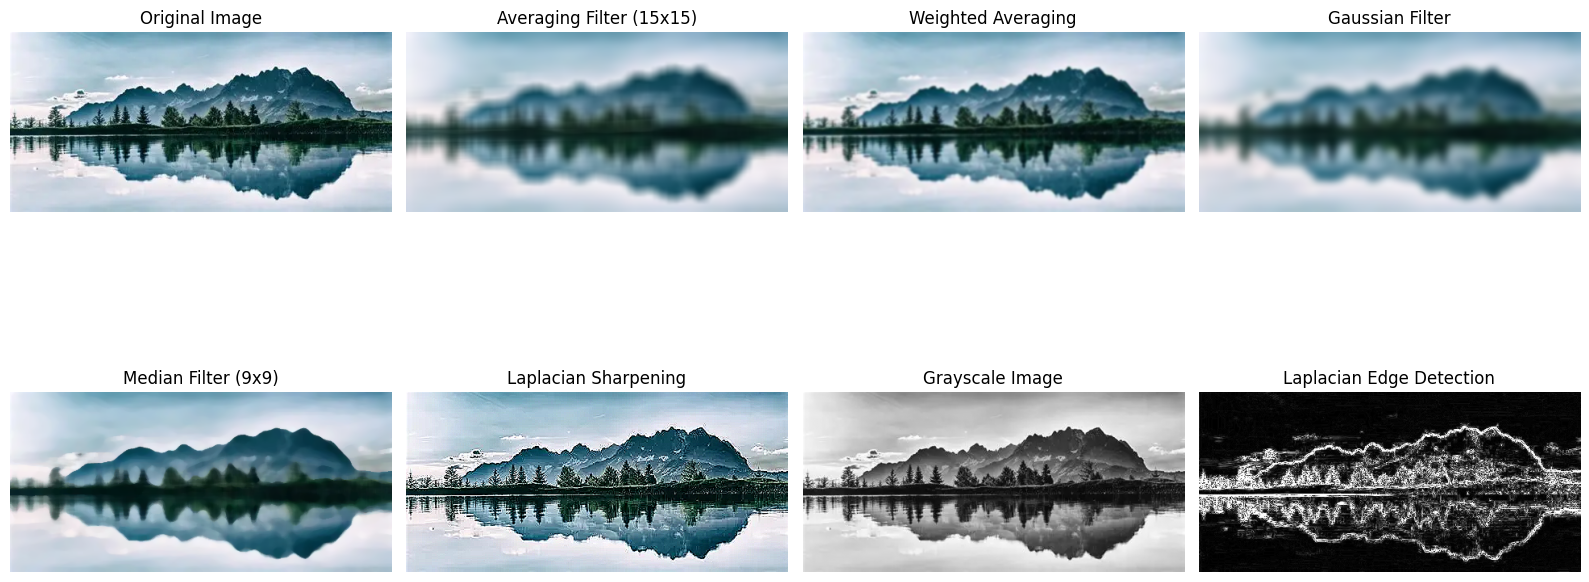

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read image
img = cv2.imread("nature.webp")

if img is None:
    raise FileNotFoundError("Please check that image.jpg exists.")

# Step 2: Convert BGR to RGB
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Step 3: Averaging Filter - stronger blur
averaging = cv2.blur(rgb, (15, 15))

# Step 4: Weighted Averaging Filter
kernel = np.array([
    [1, 1, 2, 1, 1],
    [1, 2, 4, 2, 1],
    [2, 4, 8, 4, 2],
    [1, 2, 4, 2, 1],
    [1, 1, 2, 1, 1]
], dtype=np.float32)

kernel = kernel / kernel.sum()
weighted = cv2.filter2D(rgb, -1, kernel)

# Step 5: Gaussian Filter - stronger smoothing
gaussian = cv2.GaussianBlur(rgb, (21, 21), 5)

# Step 6: Median Filter
median = cv2.medianBlur(rgb, 9)

# Step 7: Laplacian Sharpening
sharp_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

sharpened = cv2.filter2D(rgb, -1, sharp_kernel)

# Step 8: Grayscale conversion
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Step 9: Laplacian Operator
lap = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)
laplacian = cv2.convertScaleAbs(lap)

# Normalize Laplacian for better edge visibility
laplacian = cv2.normalize(
    laplacian, None, 0, 255, cv2.NORM_MINMAX
)

# Step 10: Display results
images = [
    (rgb, "Original Image"),
    (averaging, "Averaging Filter (15x15)"),
    (weighted, "Weighted Averaging"),
    (gaussian, "Gaussian Filter"),
    (median, "Median Filter (9x9)"),
    (sharpened, "Laplacian Sharpening"),
    (gray, "Grayscale Image"),
    (laplacian, "Laplacian Edge Detection")
]

plt.figure(figsize=(16, 9))

for i, (image, title) in enumerate(images):
    plt.subplot(2, 4, i + 1)

    if image.ndim == 2:
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        plt.imshow(image)

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

